In [47]:
import numpy as np
import matplotlib.pyplot as plt

In [48]:
def lms_equalizer(received, desired, num_taps=5, mu=0.01):
    """
    LMS adaptive equalizer with centered tap alignment.
    """

    weights = np.zeros(num_taps)

    # Start with the center tap passing the signal through
    center = num_taps // 2
    weights[center] = 1.0

    output = np.zeros(len(desired))
    errors = np.zeros(len(desired))

    # Start after enough samples are available on both sides
    for n in range(center, len(desired) - center):

        # Centered input window
        x = received[n-center:n+center+1]

        # Equalizer output
        y = np.dot(weights, x)

        # Desired transmitted symbol
        e = desired[n] - y

        # LMS update
        weights += mu * e * x

        output[n] = y
        errors[n] = e

    return output, errors, weights

In [49]:
# Original signal
np.random.seed(42)

desired = np.random.choice([-1, 1], 1000)

# Simple channel that causes ISI
channel = np.array([0.2, 0.6, 0.2])

# Pass signal through channel
received = np.convolve(desired, channel, mode="same")

print("Desired signal:")
print(desired[:20])

print("\nReceived signal:")
print(received[:20])

Desired signal:
[-1  1 -1 -1 -1  1 -1 -1 -1  1 -1 -1 -1 -1  1 -1  1  1  1 -1]

Received signal:
[-0.4  0.2 -0.6 -1.  -0.6  0.2 -0.6 -1.  -0.6  0.2 -0.6 -1.  -1.  -0.6
  0.2 -0.2  0.6  1.   0.6 -0.2]


In [50]:
output, errors, final_weights = lms_equalizer(
    received,
    desired,
    num_taps=5,
    mu=0.01
)

print("Final equalizer weights:")
print(final_weights)

Final equalizer weights:
[ 0.03670743 -0.40181038  1.71979395 -0.40085895  0.03459952]


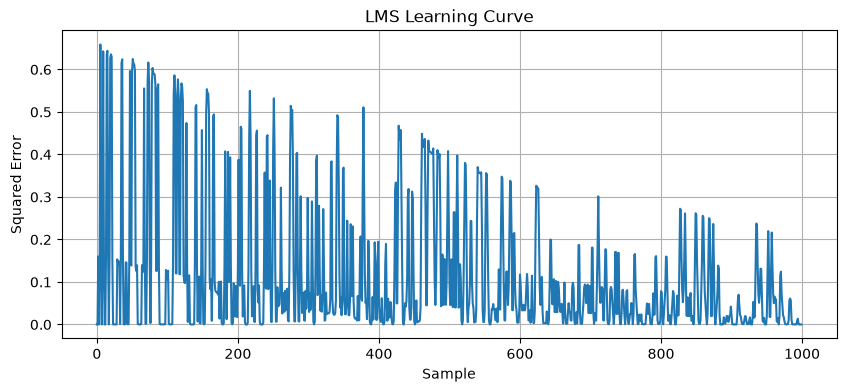

In [51]:
plt.figure(figsize=(10, 4))

plt.plot(errors**2)

plt.xlabel("Sample")
plt.ylabel("Squared Error")
plt.title("LMS Learning Curve")
plt.grid(True)

plt.show()

In [52]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from scipy.signal import convolve

In [86]:
samples_per_symbol = 10

pam4_mapping = {
    (0, 0): -3,
    (0, 1): -1,
    (1, 1): 1,
    (1, 0): 3
}

pam4_to_bits = {
    -3: (0, 0),
    -1: (0, 1),
     1: (1, 1),
     3: (1, 0)
}

channel = np.array([0.1, 0.2, 0.5, 0.2, 0.1])

channel_test = np.array([
    0.15,
    0.30,
    0.40,
    0.30,
    0.15
])

channel_test = channel_test / np.sum(channel_test)

print("Test channel:", channel_test)

num_bits = 100_000
snr_db = 15

Test channel: [0.11538462 0.23076923 0.30769231 0.23076923 0.11538462]


In [54]:
bits = np.random.randint(0, 2, num_bits)

bit_pairs = bits.reshape(-1, 2)

symbols = np.array([
    pam4_mapping[tuple(pair)]
    for pair in bit_pairs
])

tx_waveform = np.repeat(symbols, samples_per_symbol)

print("Bits:", len(bits))
print("Symbols:", len(symbols))
print("Waveform samples:", len(tx_waveform))

Bits: 100000
Symbols: 50000
Waveform samples: 500000


In [55]:
rx_noiseless = convolve(
    tx_waveform,
    channel,
    mode="same"
)

In [56]:
signal_power = np.mean(rx_noiseless ** 2)

snr_linear = 10 ** (snr_db / 10)

noise_power = signal_power / snr_linear

noise = np.random.normal(
    0,
    np.sqrt(noise_power),
    len(rx_noiseless)
)

rx_signal = rx_noiseless + noise

In [57]:
sample_indices = np.arange(
    samples_per_symbol // 2,
    len(rx_signal),
    samples_per_symbol
)

rx_samples = rx_signal[sample_indices]

print("Received symbols:", len(rx_samples))

Received symbols: 50000


In [58]:
equalized_signal, errors, lms_weights = lms_equalizer(
    rx_samples,
    symbols,
    num_taps=5,
    mu=0.01
)

In [59]:
print("Learned LMS weights:")
print(lms_weights)

Learned LMS weights:
[-0.00304265  0.05092016  0.93297506  0.05486517 -0.02443759]


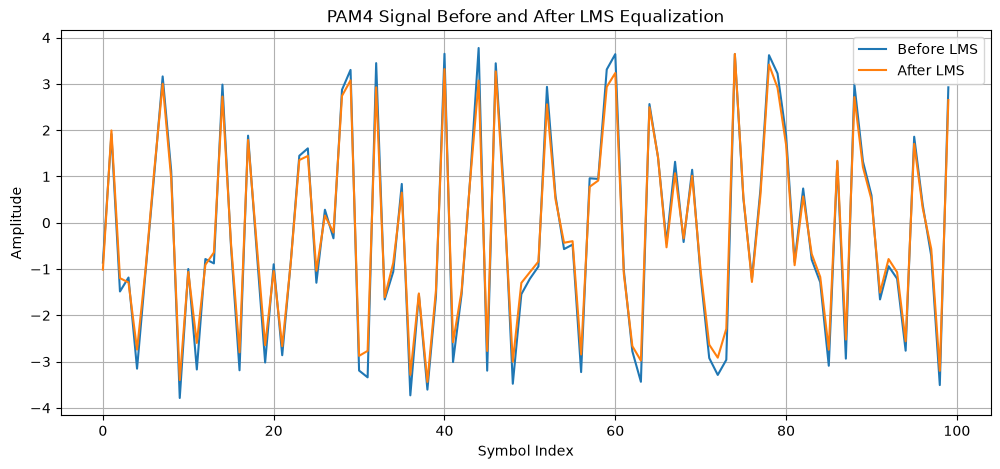

In [60]:
start = 100
end = 200

plt.figure(figsize=(12, 5))

plt.plot(rx_samples[start:end], label="Before LMS")
plt.plot(equalized_signal[start:end], label="After LMS")

plt.xlabel("Symbol Index")
plt.ylabel("Amplitude")
plt.title("PAM4 Signal Before and After LMS Equalization")
plt.legend()
plt.grid(True)

plt.show()

In [61]:
def pam4_detect(samples):
    detected = np.zeros(len(samples), dtype=int)

    detected[samples < -2] = -3
    detected[(samples >= -2) & (samples < 0)] = -1
    detected[(samples >= 0) & (samples < 2)] = 1
    detected[samples >= 2] = 3

    return detected

In [62]:
detected_symbols = pam4_detect(equalized_signal)

In [63]:
detected_bits = np.array([
    bit
    for symbol in detected_symbols
    for bit in pam4_to_bits[symbol]
])

detected_bits = detected_bits[:len(bits)]

In [64]:
bit_errors = np.sum(bits != detected_bits)

lms_ber = bit_errors / len(bits)

print("========== LMS RESULTS ==========")
print(f"SNR: {snr_db} dB")
print(f"Bit errors: {bit_errors}")
print(f"BER: {lms_ber:.6f}")

========== LMS RESULTS ==========
SNR: 15 dB
Bit errors: 552
BER: 0.005520


In [67]:
num_train_bits = 20_000
num_test_bits = 80_000

train_bits = np.random.randint(0, 2, num_train_bits)
test_bits = np.random.randint(0, 2, num_test_bits)

print("Training bits:", len(train_bits))
print("Testing bits:", len(test_bits))

Training bits: 20000
Testing bits: 80000


In [68]:
def bits_to_pam4(bits):
    bit_pairs = bits.reshape(-1, 2)

    symbols = np.array([
        pam4_mapping[tuple(pair)]
        for pair in bit_pairs
    ])

    return symbols

In [69]:
train_symbols = bits_to_pam4(train_bits)
test_symbols = bits_to_pam4(test_bits)

print("Training symbols:", len(train_symbols))
print("Testing symbols:", len(test_symbols))

Training symbols: 10000
Testing symbols: 40000


In [70]:
def apply_channel(symbols, channel, samples_per_symbol, snr_db):
    # Oversample
    tx_waveform = np.repeat(symbols, samples_per_symbol)

    # Channel
    rx_noiseless = convolve(
        tx_waveform,
        channel,
        mode="same"
    )

    # Signal power
    signal_power = np.mean(rx_noiseless ** 2)

    # SNR
    snr_linear = 10 ** (snr_db / 10)

    # Noise power
    noise_power = signal_power / snr_linear

    # AWGN
    noise = np.random.normal(
        0,
        np.sqrt(noise_power),
        len(rx_noiseless)
    )

    rx_signal = rx_noiseless + noise

    # Sample once per symbol
    sample_indices = np.arange(
        samples_per_symbol // 2,
        len(rx_signal),
        samples_per_symbol
    )

    rx_samples = rx_signal[sample_indices]

    return rx_samples

In [71]:
train_received = apply_channel(
    train_symbols,
    channel,
    samples_per_symbol,
    snr_db
)

test_received = apply_channel(
    test_symbols,
    channel,
    samples_per_symbol,
    snr_db
)

In [72]:
train_output, train_errors, trained_weights = lms_equalizer(
    train_received,
    train_symbols,
    num_taps=5,
    mu=0.01
)

In [73]:
def apply_equalizer(received, weights):
    num_taps = len(weights)
    center = num_taps // 2

    output = np.zeros(len(received))

    for n in range(center, len(received) - center):

        x = received[n-center:n+center+1]

        output[n] = np.dot(weights, x)

    return output

In [74]:
test_equalized = apply_equalizer(
    test_received,
    trained_weights
)

In [75]:
test_detected_symbols = pam4_detect(test_equalized)

In [76]:
test_detected_bits = np.array([
    bit
    for symbol in test_detected_symbols
    for bit in pam4_to_bits[symbol]
])

test_detected_bits = test_detected_bits[:len(test_bits)]

In [77]:
test_bit_errors = np.sum(test_bits != test_detected_bits)

test_ber = test_bit_errors / len(test_bits)

print("========== LMS TEST RESULTS ==========")
print(f"SNR: {snr_db} dB")
print(f"Test bit errors: {test_bit_errors}")
print(f"Test BER: {test_ber:.6f}")

========== LMS TEST RESULTS ==========
SNR: 15 dB
Test bit errors: 625
Test BER: 0.007812


In [81]:
snr_values = np.arange(0, 21, 2)

baseline_ber_results = []
lms_ber_results = []

num_train_bits = 20_000
num_test_bits = 80_000

print("SNR values:", snr_values)

SNR values: [ 0  2  4  6  8 10 12 14 16 18 20]


In [82]:
def calculate_baseline_ber(bits, channel, samples_per_symbol, snr_db):

    # Convert bits to PAM4 symbols
    symbols = bits_to_pam4(bits)

    # Pass through channel
    rx_samples = apply_channel(
        symbols,
        channel,
        samples_per_symbol,
        snr_db
    )

    # PAM4 detection
    detected_symbols = pam4_detect(rx_samples)

    # Convert detected symbols back to bits
    detected_bits = np.array([
        bit
        for symbol in detected_symbols
        for bit in pam4_to_bits[symbol]
    ])

    detected_bits = detected_bits[:len(bits)]

    # BER
    bit_errors = np.sum(bits != detected_bits)
    ber = bit_errors / len(bits)

    return ber

In [83]:
def calculate_lms_ber(
    train_bits,
    test_bits,
    channel,
    samples_per_symbol,
    snr_db,
    num_taps=5,
    mu=0.01
):

    # Convert bits to PAM4
    train_symbols = bits_to_pam4(train_bits)
    test_symbols = bits_to_pam4(test_bits)

    # Channel + noise
    train_received = apply_channel(
        train_symbols,
        channel,
        samples_per_symbol,
        snr_db
    )

    test_received = apply_channel(
        test_symbols,
        channel,
        samples_per_symbol,
        snr_db
    )

    # Train LMS
    _, _, weights = lms_equalizer(
        train_received,
        train_symbols,
        num_taps=num_taps,
        mu=mu
    )

    # Apply learned weights to test data
    test_equalized = apply_equalizer(
        test_received,
        weights
    )

    # PAM4 detection
    detected_symbols = pam4_detect(test_equalized)

    # Convert back to bits
    detected_bits = np.array([
        bit
        for symbol in detected_symbols
        for bit in pam4_to_bits[symbol]
    ])

    detected_bits = detected_bits[:len(test_bits)]

    # BER
    bit_errors = np.sum(test_bits != detected_bits)
    ber = bit_errors / len(test_bits)

    return ber

In [84]:
for snr_db in snr_values:

    # Generate fresh training/testing data
    train_bits = np.random.randint(0, 2, num_train_bits)
    test_bits = np.random.randint(0, 2, num_test_bits)

    # Baseline
    baseline_ber = calculate_baseline_ber(
        test_bits,
        channel,
        samples_per_symbol,
        snr_db
    )

    # LMS
    lms_ber = calculate_lms_ber(
        train_bits,
        test_bits,
        channel,
        samples_per_symbol,
        snr_db,
        num_taps=5,
        mu=0.01
    )

    baseline_ber_results.append(baseline_ber)
    lms_ber_results.append(lms_ber)

    print(
        f"SNR = {snr_db:2d} dB | "
        f"Baseline BER = {baseline_ber:.6f} | "
        f"LMS BER = {lms_ber:.6f}"
    )

SNR =  0 dB | Baseline BER = 0.278612 | LMS BER = 0.371988
SNR =  2 dB | Baseline BER = 0.227738 | LMS BER = 0.236125
SNR =  4 dB | Baseline BER = 0.177262 | LMS BER = 0.216888
SNR =  6 dB | Baseline BER = 0.130862 | LMS BER = 0.158963
SNR =  8 dB | Baseline BER = 0.089913 | LMS BER = 0.144300
SNR = 10 dB | Baseline BER = 0.054400 | LMS BER = 0.063062
SNR = 12 dB | Baseline BER = 0.026462 | LMS BER = 0.031988
SNR = 14 dB | Baseline BER = 0.008812 | LMS BER = 0.009888
SNR = 16 dB | Baseline BER = 0.002363 | LMS BER = 0.003525
SNR = 18 dB | Baseline BER = 0.000275 | LMS BER = 0.000188
SNR = 20 dB | Baseline BER = 0.000025 | LMS BER = 0.000037


In [87]:
# Phase 2.7.2 — Stronger channel test

strong_baseline_results = []
strong_lms_results = []

for snr_db in snr_values:

    # Generate fresh training/testing data
    train_bits = np.random.randint(0, 2, num_train_bits)
    test_bits = np.random.randint(0, 2, num_test_bits)

    # Baseline using stronger channel
    baseline_ber = calculate_baseline_ber(
        test_bits,
        channel_test,
        samples_per_symbol,
        snr_db
    )

    # LMS using stronger channel
    lms_ber = calculate_lms_ber(
        train_bits,
        test_bits,
        channel_test,
        samples_per_symbol,
        snr_db,
        num_taps=5,
        mu=0.01
    )

    strong_baseline_results.append(baseline_ber)
    strong_lms_results.append(lms_ber)

    print(
        f"SNR = {snr_db:2d} dB | "
        f"Baseline BER = {baseline_ber:.6f} | "
        f"LMS BER = {lms_ber:.6f}"
    )

SNR =  0 dB | Baseline BER = 0.273850 | LMS BER = 0.298425
SNR =  2 dB | Baseline BER = 0.221663 | LMS BER = 0.275213
SNR =  4 dB | Baseline BER = 0.174950 | LMS BER = 0.251862
SNR =  6 dB | Baseline BER = 0.128137 | LMS BER = 0.164788
SNR =  8 dB | Baseline BER = 0.085825 | LMS BER = 0.095687
SNR = 10 dB | Baseline BER = 0.048513 | LMS BER = 0.069300
SNR = 12 dB | Baseline BER = 0.021087 | LMS BER = 0.023238
SNR = 14 dB | Baseline BER = 0.006188 | LMS BER = 0.008238
SNR = 16 dB | Baseline BER = 0.001025 | LMS BER = 0.001150
SNR = 18 dB | Baseline BER = 0.000087 | LMS BER = 0.000188
SNR = 20 dB | Baseline BER = 0.000000 | LMS BER = 0.000025


In [89]:
# Compare received and equalized samples

train_bits = np.random.randint(0, 2, num_train_bits)
test_bits = np.random.randint(0, 2, num_test_bits)

test_symbols = bits_to_pam4(test_bits)

test_received = apply_channel(
    test_symbols,
    channel_test,
    samples_per_symbol,
    14
)

# Train LMS
train_symbols = bits_to_pam4(train_bits)

train_received = apply_channel(
    train_symbols,
    channel_test,
    samples_per_symbol,
    14
)

_, _, weights = lms_equalizer(
    train_received,
    train_symbols,
    num_taps=5,
    mu=0.01
)

# Apply equalizer
test_equalized = apply_equalizer(
    test_received,
    weights
)

print("Learned weights:")
print(weights)

Learned weights:
[-0.04355785  0.00269421  0.92290633 -0.03096681  0.031712  ]


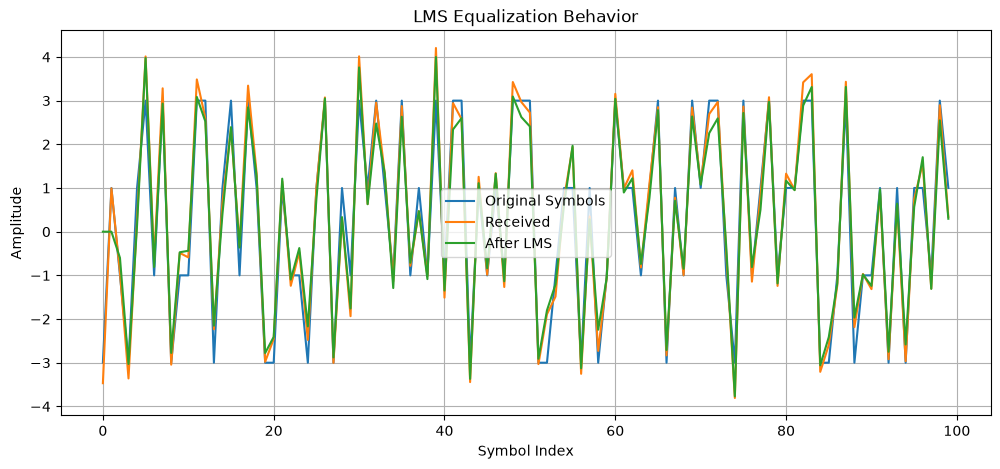

In [90]:
plt.figure(figsize=(12, 5))

plt.plot(test_symbols[:100], label="Original Symbols")
plt.plot(test_received[:100], label="Received")
plt.plot(test_equalized[:100], label="After LMS")

plt.xlabel("Symbol Index")
plt.ylabel("Amplitude")
plt.title("LMS Equalization Behavior")
plt.legend()
plt.grid(True)

plt.show()

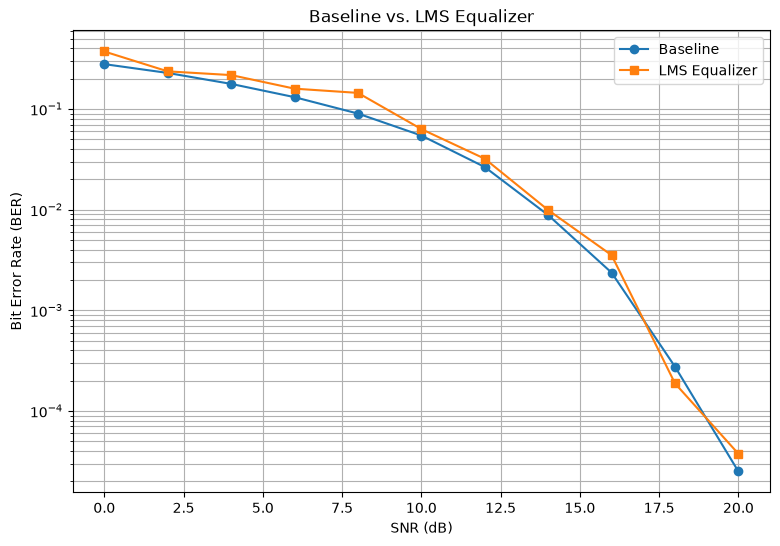

In [88]:
plt.figure(figsize=(9, 6))

plt.semilogy(
    snr_values,
    baseline_ber_results,
    "o-",
    label="Baseline"
)

plt.semilogy(
    snr_values,
    lms_ber_results,
    "s-",
    label="LMS Equalizer"
)

plt.xlabel("SNR (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.title("Baseline vs. LMS Equalizer")
plt.legend()
plt.grid(True, which="both")

plt.show()

In [91]:
def apply_channel_fse(
    symbols,
    channel,
    samples_per_symbol,
    snr_db,
    fse_samples_per_symbol=2
):
    """
    Generate received samples for a fractionally-spaced equalizer.
    """

    # Oversample transmitted PAM4 symbols
    tx_waveform = np.repeat(symbols, samples_per_symbol)

    # Apply channel
    rx_noiseless = convolve(
        tx_waveform,
        channel,
        mode="same"
    )

    # Calculate noise power
    signal_power = np.mean(rx_noiseless ** 2)
    snr_linear = 10 ** (snr_db / 10)
    noise_power = signal_power / snr_linear

    # Add AWGN
    noise = np.random.normal(
        0,
        np.sqrt(noise_power),
        len(rx_noiseless)
    )

    rx_signal = rx_noiseless + noise

    # Select evenly spaced samples
    spacing = samples_per_symbol // fse_samples_per_symbol

    sample_indices = np.arange(
        samples_per_symbol // 2,
        len(rx_signal),
        spacing
    )

    rx_samples = rx_signal[sample_indices]

    return rx_samples

In [92]:
test_bits = np.random.randint(0, 2, 1000)

test_symbols = bits_to_pam4(test_bits)

test_fse_received = apply_channel_fse(
    test_symbols,
    channel_test,
    samples_per_symbol,
    snr_db=14,
    fse_samples_per_symbol=2
)

print("Number of transmitted symbols:", len(test_symbols))
print("Number of FSE samples:", len(test_fse_received))

Number of transmitted symbols: 500
Number of FSE samples: 999


In [93]:
print(test_fse_received[:20])

[ 1.00543206  2.32508507  3.0869623   1.46200273  1.28530949  0.05414125
 -0.8779765  -0.28188195 -1.62831992  1.45912023  2.8450849  -0.50005137
 -1.04552706  0.46475349  1.21404101 -2.37658114 -2.55330481 -0.40959387
  1.65434113  3.14253982]


In [95]:
def fse_lms_equalizer(
    received,
    desired,
    samples_per_symbol=2,
    num_taps=5,
    mu=0.001
):
    """
    Fractionally-spaced LMS equalizer.

    received:
        Multiple samples per symbol.

    desired:
        One desired PAM4 symbol per symbol.
    """

    weights = np.zeros(num_taps)

    # Center tap initialization
    center = num_taps // 2
    weights[center] = 1.0

    output = np.zeros(len(desired))
    errors = np.zeros(len(desired))

    # Convert received samples into symbol-spaced groups
    num_symbols = min(
        len(desired),
        len(received) // samples_per_symbol
    )

    for n in range(center, num_symbols - center):

        start = (
            n * samples_per_symbol
            - center
        )

        # Gather neighboring samples
        x = received[
            start : start + num_taps
        ]

        if len(x) != num_taps:
            continue

        # Equalizer output
        y = np.dot(weights, x)

        # Error
        e = desired[n] - y

        # LMS update
        weights += mu * e * x

        output[n] = y
        errors[n] = e

    return output, errors, weights

In [96]:
train_bits = np.random.randint(0, 2, 2000)

train_symbols = bits_to_pam4(train_bits)

train_received = apply_channel_fse(
    train_symbols,
    channel_test,
    samples_per_symbol,
    snr_db=14,
    fse_samples_per_symbol=2
)

fse_output, fse_errors, fse_weights = fse_lms_equalizer(
    train_received,
    train_symbols,
    samples_per_symbol=2,
    num_taps=5,
    mu=0.001
)

print("FSE-LMS weights:")
print(fse_weights)

FSE-LMS weights:
[-0.03302051  0.03709878  0.91567465  0.01655264 -0.0157334 ]


In [97]:
def calculate_fse_lms_ber(
    train_bits,
    test_bits,
    channel,
    samples_per_symbol,
    snr_db,
    fse_samples_per_symbol=2,
    num_taps=5,
    mu=0.001
):
    
    # Convert bits to PAM4 symbols
    train_symbols = bits_to_pam4(train_bits)
    test_symbols = bits_to_pam4(test_bits)

    # Generate received training signal
    train_received = apply_channel_fse(
        train_symbols,
        channel,
        samples_per_symbol,
        snr_db,
        fse_samples_per_symbol
    )

    # Generate received testing signal
    test_received = apply_channel_fse(
        test_symbols,
        channel,
        samples_per_symbol,
        snr_db,
        fse_samples_per_symbol
    )

    # Train FSE-LMS
    _, _, weights = fse_lms_equalizer(
        train_received,
        train_symbols,
        samples_per_symbol=fse_samples_per_symbol,
        num_taps=num_taps,
        mu=mu
    )

    # Apply learned weights to test data
    test_output = np.zeros(len(test_symbols))

    center = num_taps // 2

    for n in range(
        center,
        len(test_symbols) - center
    ):

        start = (
            n * fse_samples_per_symbol
            - center
        )

        x = test_received[
            start : start + num_taps
        ]

        if len(x) != num_taps:
            continue

        test_output[n] = np.dot(
            weights,
            x
        )

    # PAM4 detection
    detected_symbols = pam4_detect(test_output)

    # Convert detected symbols → bits
    detected_bits = np.array([
        bit
        for symbol in detected_symbols
        for bit in pam4_to_bits[symbol]
    ])

    detected_bits = detected_bits[:len(test_bits)]

    # Calculate BER
    bit_errors = np.sum(
        test_bits != detected_bits
    )

    ber = bit_errors / len(test_bits)

    return ber

In [98]:
test_snr = 14

train_bits = np.random.randint(
    0, 2, num_train_bits
)

test_bits = np.random.randint(
    0, 2, num_test_bits
)

fse_lms_ber = calculate_fse_lms_ber(
    train_bits,
    test_bits,
    channel_test,
    samples_per_symbol,
    test_snr,
    fse_samples_per_symbol=2,
    num_taps=5,
    mu=0.001
)

print("========== FSE-LMS RESULT ==========")
print(f"SNR: {test_snr} dB")
print(f"FSE-LMS BER: {fse_lms_ber:.6f}")

========== FSE-LMS RESULT ==========
SNR: 14 dB
FSE-LMS BER: 0.001762


In [99]:
fse_lms_ber_results = []

for snr_db in snr_values:

    # Generate fresh training/testing data
    train_bits = np.random.randint(
        0, 2, num_train_bits
    )

    test_bits = np.random.randint(
        0, 2, num_test_bits
    )

    # Calculate FSE-LMS BER
    ber = calculate_fse_lms_ber(
        train_bits,
        test_bits,
        channel_test,
        samples_per_symbol,
        snr_db,
        fse_samples_per_symbol=2,
        num_taps=5,
        mu=0.001
    )

    fse_lms_ber_results.append(ber)

    print(
        f"SNR = {snr_db:2d} dB | "
        f"FSE-LMS BER = {ber:.6f}"
    )

SNR =  0 dB | FSE-LMS BER = 0.243250
SNR =  2 dB | FSE-LMS BER = 0.191688
SNR =  4 dB | FSE-LMS BER = 0.144563
SNR =  6 dB | FSE-LMS BER = 0.099750
SNR =  8 dB | FSE-LMS BER = 0.062700
SNR = 10 dB | FSE-LMS BER = 0.028475
SNR = 12 dB | FSE-LMS BER = 0.008712
SNR = 14 dB | FSE-LMS BER = 0.001538
SNR = 16 dB | FSE-LMS BER = 0.000162
SNR = 18 dB | FSE-LMS BER = 0.000025
SNR = 20 dB | FSE-LMS BER = 0.000013


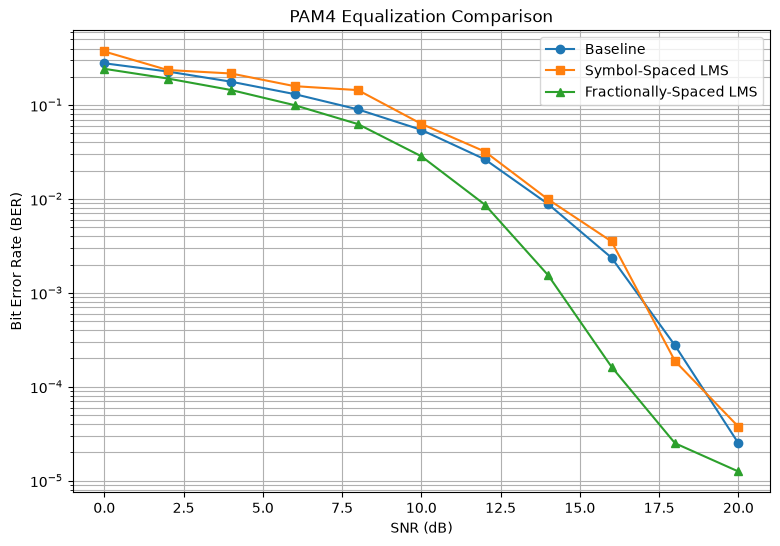

In [100]:
plt.figure(figsize=(9, 6))

plt.semilogy(
    snr_values,
    baseline_ber_results,
    "o-",
    label="Baseline"
)

plt.semilogy(
    snr_values,
    lms_ber_results,
    "s-",
    label="Symbol-Spaced LMS"
)

plt.semilogy(
    snr_values,
    fse_lms_ber_results,
    "^-",
    label="Fractionally-Spaced LMS"
)

plt.xlabel("SNR (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.title("PAM4 Equalization Comparison")
plt.legend()
plt.grid(True, which="both")

plt.show()

In [101]:
import time

# Generate a fixed test signal
timing_bits = np.random.randint(0, 2, 20_000)
timing_symbols = bits_to_pam4(timing_bits)

timing_received = apply_channel_fse(
    timing_symbols,
    channel_test,
    samples_per_symbol,
    snr_db=14,
    fse_samples_per_symbol=2
)

# Time the LMS equalizer
start_time = time.perf_counter()

timed_output, timed_errors, timed_weights = fse_lms_equalizer(
    timing_received,
    timing_symbols,
    samples_per_symbol=2,
    num_taps=5,
    mu=0.001
)

end_time = time.perf_counter()

training_time = end_time - start_time

print(f"LMS training time: {training_time:.6f} seconds")

LMS training time: 0.018043 seconds


In [102]:
# Measure LMS inference latency

# Use the weights we already trained
start_time = time.perf_counter()

inference_output = np.zeros(len(timing_symbols))

center = 5 // 2

for n in range(center, len(timing_symbols) - center):

    start = n * 2 - center

    x = timing_received[start:start + 5]

    if len(x) != 5:
        continue

    inference_output[n] = np.dot(
        timed_weights,
        x
    )

end_time = time.perf_counter()

inference_time = end_time - start_time

print(f"LMS inference time: {inference_time:.6f} seconds")

LMS inference time: 0.014055 seconds


In [105]:
# ============================================
# LMS SANITY CHECK — 14 dB
# ============================================

snr_db = 14

# Generate a fresh test sequence
bits_check = np.random.randint(0, 2, 20000)
symbols_check = bits_to_pam4(bits_check)

# Pass through the channel
received_check = apply_channel(
    symbols_check,
    channel_test,
    samples_per_symbol=2,
    snr_db=snr_db
)

# Baseline decisions
baseline_decisions = pam4_detect(received_check)

# LMS equalization
lms_output, lms_error, lms_weights = lms_equalizer(
    received_check,
    symbols_check,
    num_taps=5,
    mu=0.001
)

# Convert LMS output to PAM4 decisions
lms_decisions = pam4_detect(lms_output)

print("Final LMS weights:")
print(lms_weights)

Final LMS weights:
[-0.11851361 -0.04042334  1.73980294 -0.90578874  0.35645411]


In [106]:
baseline_errors = np.sum(
    baseline_decisions != symbols_check
)

lms_errors = np.sum(
    lms_decisions != symbols_check
)

print("Baseline symbol errors:", baseline_errors)
print("LMS symbol errors:", lms_errors)

print(
    "Baseline SER:",
    baseline_errors / len(symbols_check)
)

print(
    "LMS SER:",
    lms_errors / len(symbols_check)
)

Baseline symbol errors: 4895
LMS symbol errors: 2924
Baseline SER: 0.4895
LMS SER: 0.2924


In [109]:
# ============================================
# STANDARDIZED INFERENCE BENCHMARK
# ============================================

BENCHMARK_SYMBOLS = 10_000
NUM_RUNS = 20

print("Benchmark symbols:", BENCHMARK_SYMBOLS)
print("Timing runs:", NUM_RUNS)

Benchmark symbols: 10000
Timing runs: 20


In [110]:
# ============================================
# LMS INFERENCE BENCHMARK
# ============================================

import time

benchmark_bits = np.random.randint(
    0, 2, BENCHMARK_SYMBOLS * 2
)

benchmark_symbols = bits_to_pam4(benchmark_bits)

benchmark_received = apply_channel(
    benchmark_symbols,
    channel_test,
    samples_per_symbol=2,
    snr_db=14
)

# Warm-up
_ = lms_equalizer(
    benchmark_received,
    benchmark_symbols,
    num_taps=5,
    mu=0.001
)

times = []

for _ in range(NUM_RUNS):

    start = time.perf_counter()

    _ = lms_equalizer(
        benchmark_received,
        benchmark_symbols,
        num_taps=5,
        mu=0.001
    )

    end = time.perf_counter()

    times.append(end - start)

lms_benchmark_time = np.mean(times)

print(
    f"LMS inference time for "
    f"{BENCHMARK_SYMBOLS:,} symbols: "
    f"{lms_benchmark_time:.6f} s"
)

print(
    f"LMS time per symbol: "
    f"{lms_benchmark_time / BENCHMARK_SYMBOLS:.9f} s"
)

LMS inference time for 10,000 symbols: 0.020390 s
LMS time per symbol: 0.000002039 s
